### SIF retrieval bias vs aerosol optical depth — GCHPIO aerosols, 0.05 cm⁻¹ grid (n = 1000)

Same analysis as `compare_retrieval_bias_against_aod.ipynb`, for the ensemble generated by
`generate_test_spec_lambertian_gchpio.jl` (TOMAS bin-resolved aerosol optics, 0.05 cm⁻¹ spectral grid, δBGE truncation).

* AOD comes from the ensemble itself (`aod`, GCHPIO column AOD at each OCI band centre), so it is exactly the aerosol that went into the RT.
  The GCHP column file (`gchp_ocean_columns_n500.nc`) is only used for the sea-salt fraction at 550 nm (species path, a composition indicator).
* Two retrievals of the same spectra: **w756** (640–756 nm) and **O2A** (640–780 nm).
* ΔSIF = retrieved − true water-leaving SIF, both as point values at the OCI band nearest 678.2 nm (678.205 nm; `sif_678_true`, `sif_678_ret` of the retrieval files).
  The ensemble `sif_678` is the amplitude at 678.0 nm (≈ 1.4 % lower) and is only used as a consistency check (`sif_678_amplitude`).
  At 0.05 cm⁻¹ many O2A fits stop at the 15-iteration cap (`status = 0`)
  and the converged subset is not representative, so the samples used are chosen with `status` (list of status codes; `[-1]` = all samples).

In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

base = "/home/zhe2/FraLab/PACE_redSIF_PACE/surrogate_meas/full_RT_construction"
run_dir = f"{base}/output_new_Lambertian_gchpio_finerwavnum0p05"

# RT-generated samples (GCHPIO aerosols); `aod` is (sample, band)
rt_samples = xr.open_dataset(f"{run_dir}/rt_toa_ensemble_lambertian_gchpio_n1000.nc")

# retrievals to be evaluated (same spectra, two fitting windows)
retrieval_names = {
    "w756 (640–756 nm)": f"{run_dir}/rt_retrieval_1000_SIF678BandMismatch_nPC15_npoly3.nc",
    "O2A (640–780 nm)":  f"{run_dir}/rt_retrieval_1000_O2A_SIF678BandMismatch_nPC15_npoly2.nc",
}
retrievals = {k: xr.open_dataset(v) for k, v in retrieval_names.items()}


# GCHP column file: only for the sea-salt fraction (species path, 550 nm)
columns = xr.open_dataset(f"{base}/output_aerosol_profiles/gchp_ocean_columns_n500.nc")

# status codes to include: 1 = converged, 0 = hit the iteration cap, 2 = other stop; [-1] = all
status = [-1]
STATUS_LABEL = "all status" if -1 in status else "status " + ",".join(map(str, status))
UNITS = r"W m$^{-2}$ sr$^{-1}$ µm$^{-1}$"
print({k: v for k, v in rt_samples.attrs.items() if k in
       ("n_completed", "n_samples", "seed", "aerosol_optics", "aerosol_truncation", "ocean_yaml")})

{'n_completed': np.int32(1000), 'n_samples': np.int32(1000), 'seed': np.int32(20260913), 'ocean_yaml': '/home/zhe2/FraLab/PACE_redSIF_PACE/surrogate_meas/full_RT_construction/../configs/ocean_lambertian_1010_wavnum0p05.yaml', 'aerosol_optics': 'Google-RT GCHPIO TOMAS bin-resolved Mie, layer-resolved', 'aerosol_truncation': 'δBGE{Float64}'}


In [2]:
# per-sample AOD from the ensemble (GCHPIO), interpolated to fixed wavelengths
wl = rt_samples.wavelength.values
aod_band = rt_samples.aod.transpose("sample", "band").values            # (sample, band)
aod_at = lambda lam: np.array([np.interp(lam, wl, a) for a in aod_band])
aod_678 = aod_at(678.0)
aod_640, aod_780 = aod_at(640.0), aod_at(780.0)
angstrom = -np.log(aod_640 / aod_780) / np.log(640.0 / 780.0)         # Ångström exponent 640→780 nm

column_index = rt_samples.column_index.values                          # 1-based
assert column_index.min() >= 1, "aerosols were disabled in this ensemble (column_index = 0)"
icol = column_index - 1
ss_fraction = columns.ss_fraction.values[icol]                         # species path, 550 nm
aod_file_550 = columns.tau_ref.values[icol]

# retrieval results; truth and retrieval both as point values at the band nearest 678.2 nm
sif_678_amp = rt_samples.sif_678.values                                 # amplitude at 678.0 nm
sif_678_true = None
res = {}
for name, r in retrievals.items():
    assert np.allclose(r.sif_678_amplitude.values, sif_678_amp), name
    t_pt = r.sif_678_true.values
    if sif_678_true is None:
        sif_678_true, band_nm = t_pt, float(r.attrs["sif_band_nm"])
    assert np.allclose(t_pt, sif_678_true), name
    st = r.status.values
    res[name] = dict(delta=r.sif_678_ret.values - t_pt, status=st,
                     sel=np.isfinite(r.sif_678_ret.values) & (True if -1 in status else np.isin(st, status)))
    print(f"{name:20s} samples {st.size}, converged {np.sum(st == 1)}, "
          f"status counts {dict(zip(*np.unique(st, return_counts=True)))}, using {res[name]['sel'].sum()} ({STATUS_LABEL})")
print(f"SIF compared at {band_nm:.3f} nm (point value); median truth / 678.0-nm amplitude = "
      f"{np.median(sif_678_true[sif_678_amp > 0.05] / sif_678_amp[sif_678_amp > 0.05]):.4f}")

w756 (640–756 nm)    samples 1000, converged 988, status counts {np.int16(0): np.int64(11), np.int16(1): np.int64(988), np.int16(2): np.int64(1)}, using 1000 (all status)
O2A (640–780 nm)     samples 1000, converged 185, status counts {np.int16(0): np.int64(737), np.int16(1): np.int64(185), np.int16(2): np.int64(78)}, using 1000 (all status)
SIF compared at 678.205 nm (point value); median truth / 678.0-nm amplitude = 1.0136


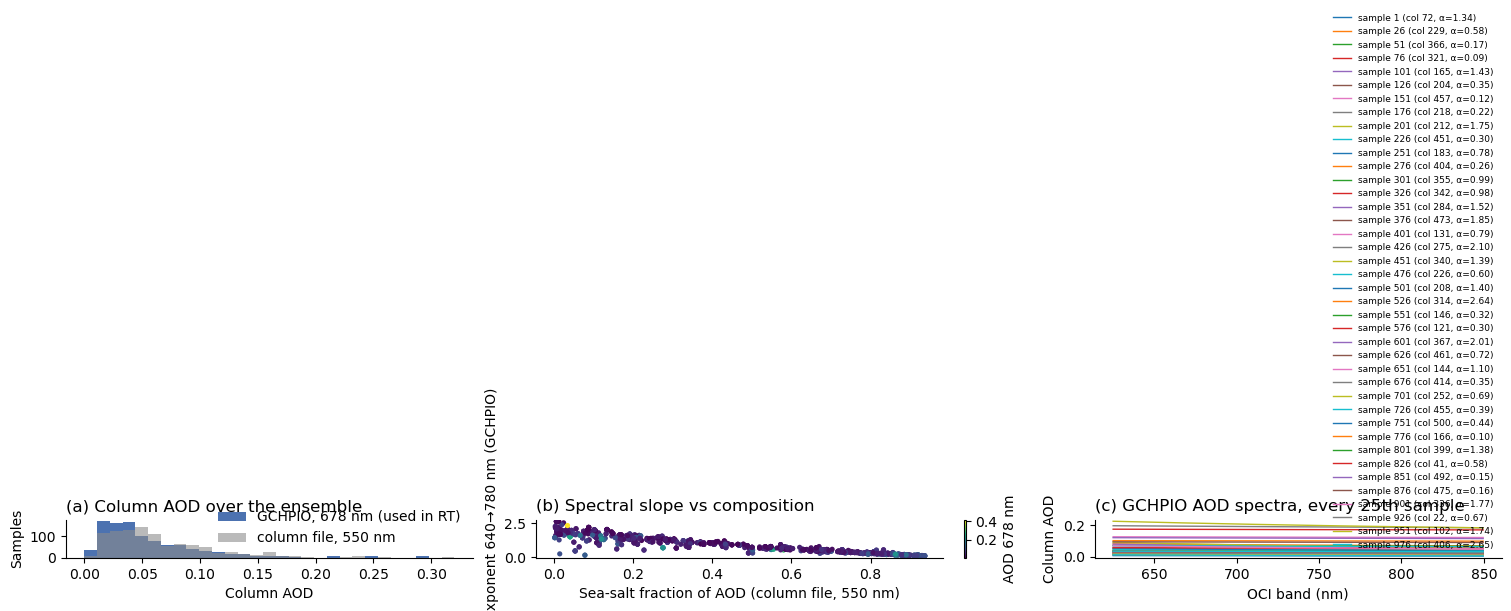

AOD(678): median 0.041, 5–95% [0.012, 0.143];  Ångström: median 0.67, 5–95% [0.13, 2.01]


In [3]:
# overview of the aerosol in the ensemble
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout="constrained")
bins = np.linspace(0, np.percentile(np.r_[aod_678, aod_file_550], 99.5), 30)
axes[0].hist(aod_678, bins=bins, color="#4C72B0", label="GCHPIO, 678 nm (used in RT)")
axes[0].hist(aod_file_550, bins=bins, color="0.55", alpha=0.6, label="column file, 550 nm")
axes[0].set_xlabel("Column AOD")
axes[0].set_ylabel("Samples")
axes[0].set_title("(a) Column AOD over the ensemble", loc="left")
axes[0].legend(frameon=False)

sc = axes[1].scatter(ss_fraction, angstrom, c=aod_678, s=14, cmap="viridis", linewidths=0)
axes[1].set_xlabel("Sea-salt fraction of AOD (column file, 550 nm)")
axes[1].set_ylabel("Ångström exponent 640→780 nm (GCHPIO)")
axes[1].set_title("(b) Spectral slope vs composition", loc="left")
fig.colorbar(sc, ax=axes[1], label="AOD 678 nm")

for i in range(0, aod_band.shape[0], 25):
    axes[2].plot(wl, aod_band[i], lw=1, label=f"sample {i + 1} (col {column_index[i]}, α={angstrom[i]:.2f})")
axes[2].set_xlabel("OCI band (nm)")
axes[2].set_ylabel("Column AOD")
axes[2].set_title("(c) GCHPIO AOD spectra, every 25th sample", loc="left")
axes[2].legend(fontsize=6.5, frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.show()
print(f"AOD(678): median {np.median(aod_678):.3f}, 5–95% [{np.percentile(aod_678, 5):.3f}, {np.percentile(aod_678, 95):.3f}];  "
      f"Ångström: median {np.median(angstrom):.2f}, 5–95% [{np.percentile(angstrom, 5):.2f}, {np.percentile(angstrom, 95):.2f}]")

w756 (640–756 nm): ΔSIF (n=1000) mean -0.0325, median -0.0316, SD 0.0195, RMSE 0.0379;  relative (true SIF > 0.05) median -12.3 %
O2A (640–780 nm): ΔSIF (n=1000) mean -0.0229, median -0.0220, SD 0.0257, RMSE 0.0344;  relative (true SIF > 0.05) median -8.7 %


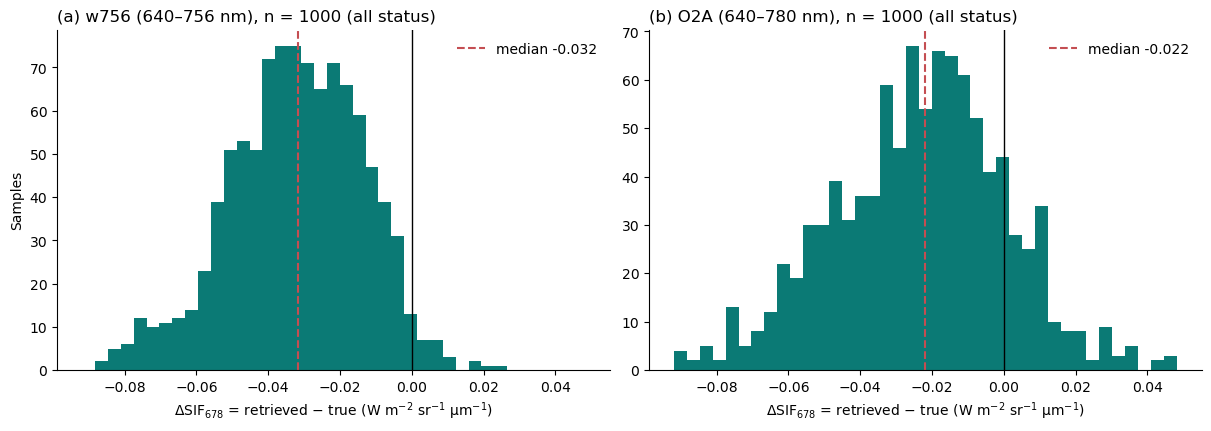

In [4]:
# histogram of ΔSIF per retrieval window (selected samples)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained", sharex=True)
lo, hi = np.percentile(np.concatenate([v["delta"][v["sel"]] for v in res.values()]), [0.5, 99.5])
for ax, (name, v), letter in zip(axes, res.items(), "ab"):
    d = v["delta"][v["sel"]]
    t = sif_678_true[v["sel"]]
    rel = d / np.where(np.abs(t) > 0.05, t, np.nan) * 100
    print(f"{name}: ΔSIF (n={d.size}) mean {d.mean():+.4f}, median {np.median(d):+.4f}, SD {d.std():.4f}, "
          f"RMSE {np.sqrt(np.mean(d**2)):.4f};  relative (true SIF > 0.05) median {np.nanmedian(rel):+.1f} %")
    ax.hist(d, bins=np.linspace(lo, hi, 40), color="#0B7A75")
    ax.axvline(0, color="k", lw=1)
    ax.axvline(np.median(d), color="#C44E52", lw=1.5, ls="--", label=f"median {np.median(d):+.3f}")
    ax.set_xlabel(f"ΔSIF$_{{678}}$ = retrieved − true ({UNITS})")
    ax.set_title(f"({letter}) {name}, n = {d.size} ({STATUS_LABEL})", loc="left")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Samples")
plt.show()

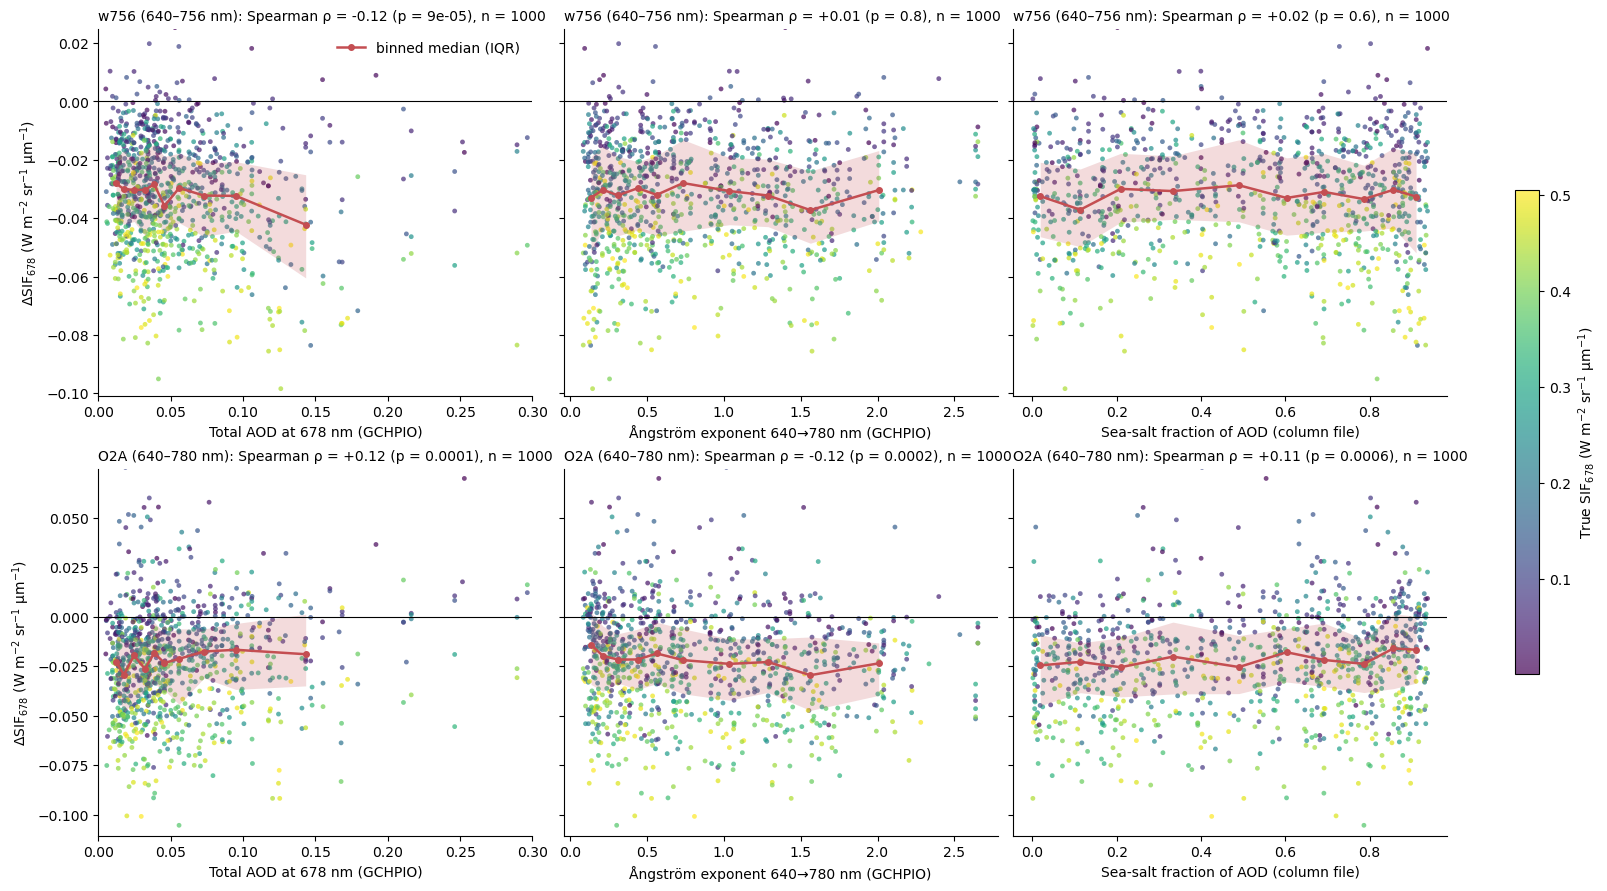

w756 (640–756 nm)    AOD678, backscatter side (vaz > 90°)   n= 480  Spearman ρ = -0.12 (p = 0.008)
w756 (640–756 nm)    AOD678, forward side (vaz ≤ 90°)       n= 520  Spearman ρ = -0.12 (p = 0.005)
w756 (640–756 nm)    AOD678, SZA < 40°                      n= 556  Spearman ρ = -0.15 (p = 0.0003)
w756 (640–756 nm)    AOD678, SZA ≥ 40°                      n= 444  Spearman ρ = -0.10 (p = 0.04)
O2A (640–780 nm)     AOD678, backscatter side (vaz > 90°)   n= 480  Spearman ρ = +0.16 (p = 0.0003)
O2A (640–780 nm)     AOD678, forward side (vaz ≤ 90°)       n= 520  Spearman ρ = +0.07 (p = 0.1)
O2A (640–780 nm)     AOD678, SZA < 40°                      n= 556  Spearman ρ = +0.05 (p = 0.2)
O2A (640–780 nm)     AOD678, SZA ≥ 40°                      n= 444  Spearman ρ = +0.20 (p = 3e-05)


In [5]:
# ΔSIF against aerosol predictors, with binned medians (quantile bins → equal counts)
def binned_median(x, y, edges, min_n=8):
    k = np.clip(np.digitize(x, edges) - 1, 0, len(edges) - 2)
    mid, med, q1, q3 = [], [], [], []
    for i in range(len(edges) - 1):
        m = k == i
        if m.sum() >= min_n:
            mid.append(np.median(x[m]))
            q = np.percentile(y[m], [25, 50, 75])
            q1.append(q[0]); med.append(q[1]); q3.append(q[2])
    return map(np.asarray, (mid, med, q1, q3))

predictors = [
    ("Total AOD at 678 nm (GCHPIO)", aod_678),
    ("Ångström exponent 640→780 nm (GCHPIO)", angstrom),
    ("Sea-salt fraction of AOD (column file)", ss_fraction),
]
fig, axes = plt.subplots(len(res), 3, figsize=(16, 4.4 * len(res)), sharey="row", layout="constrained")
for row, (name, v) in enumerate(res.items()):
    sel = v["sel"]
    y = v["delta"][sel]
    nbin = 10 if sel.sum() >= 150 else 5
    for col, (pname, x_all) in enumerate(predictors):
        ax = axes[row, col]
        x = x_all[sel]
        sc = ax.scatter(x, y, s=12, c=sif_678_true[sel], cmap="viridis", alpha=0.7, linewidths=0)
        mid, med, q1, q3 = binned_median(x, y, np.quantile(x, np.linspace(0, 1, nbin + 1)))
        ax.fill_between(mid, q1, q3, color="#C44E52", alpha=0.2, linewidth=0)
        ax.plot(mid, med, "o-", color="#C44E52", lw=1.8, ms=4, label="binned median (IQR)")
        ax.axhline(0, color="k", lw=0.8)
        rho, p = stats.spearmanr(x, y)
        ax.set_title(f"{name}: Spearman ρ = {rho:+.2f} (p = {p:.1g}), n = {sel.sum()}", loc="left", fontsize=10)
        ax.set_xlabel(pname)
        ax.set_xlim(0, 0.3) if col == 0 else None
        ax.spines[["top", "right"]].set_visible(False)
    axes[row, 0].set_ylabel(f"ΔSIF$_{{678}}$ ({UNITS})")
    lo, hi = np.percentile(y, [1, 99])
    axes[row, 0].set_ylim(lo - 0.2 * (hi - lo), hi + 0.2 * (hi - lo))
axes[0, 0].legend(frameon=False, loc="upper right")
fig.colorbar(sc, ax=axes, label=f"True SIF$_{{678}}$ ({UNITS})", shrink=0.6)
plt.show()

# does the AOD dependence survive once geometry is accounted for?
vaz, sza = rt_samples.vaz.values, rt_samples.sza.values
for name, v in res.items():
    sel = v["sel"]
    for lab, m in (("backscatter side (vaz > 90°)", vaz > 90), ("forward side (vaz ≤ 90°)", vaz <= 90),
                   ("SZA < 40°", sza < 40), ("SZA ≥ 40°", sza >= 40)):
        mm = sel & m
        rho, p = stats.spearmanr(aod_678[mm], v["delta"][mm])
        print(f"{name:20s} AOD678, {lab:30s} n={mm.sum():4d}  Spearman ρ = {rho:+.2f} (p = {p:.1g})")

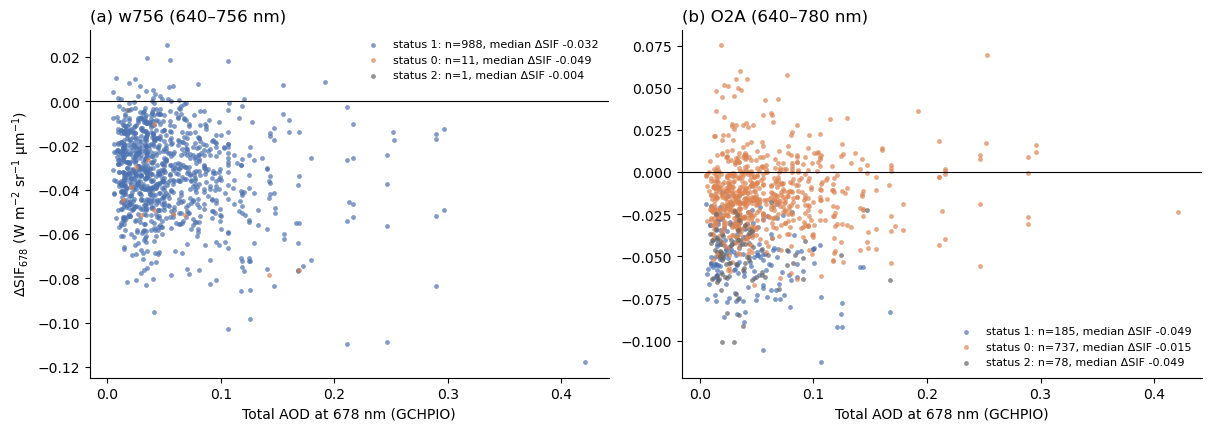

w756 (640–756 nm): AOD678 median converged 0.042 vs not 0.041 (Mann–Whitney p = 0.96)
O2A (640–780 nm): AOD678 median converged 0.034 vs not 0.045 (Mann–Whitney p = 9.4e-06)


In [6]:
# convergence check: is the converged subset representative? (status 1 = converged, 0 = hit the iteration cap)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
for ax, (name, v), letter in zip(axes, res.items(), "ab"):
    for s, col in ((1, "#4C72B0"), (0, "#DD8452"), (2, "0.4")):
        m = v["status"] == s
        if m.sum() == 0:
            continue
        ax.scatter(aod_678[m], v["delta"][m], s=12, color=col, alpha=0.7, linewidths=0,
                   label=f"status {s}: n={m.sum()}, median ΔSIF {np.median(v['delta'][m]):+.3f}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Total AOD at 678 nm (GCHPIO)")
    ax.set_title(f"({letter}) {name}", loc="left")
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"ΔSIF$_{{678}}$ ({UNITS})")
plt.show()
for name, v in res.items():
    a1, a0 = aod_678[v["status"] == 1], aod_678[v["status"] == 0]
    if a0.size and a1.size:
        print(f"{name}: AOD678 median converged {np.median(a1):.3f} vs not {np.median(a0):.3f} "
              f"(Mann–Whitney p = {stats.mannwhitneyu(a1, a0).pvalue:.2g})")

### Retrieved vs true SIF at 678.0 nm by convergence status

All samples, independent of `status`. Truth is the ensemble amplitude at exactly 678.0 nm (`sif_678_amplitude`); the retrieval at the
678.2 nm band is moved to 678.0 nm with the ratio of the first SIF singular vector, u₁(678.0) / u₁(band centre), so both sides refer to the same wavelength.


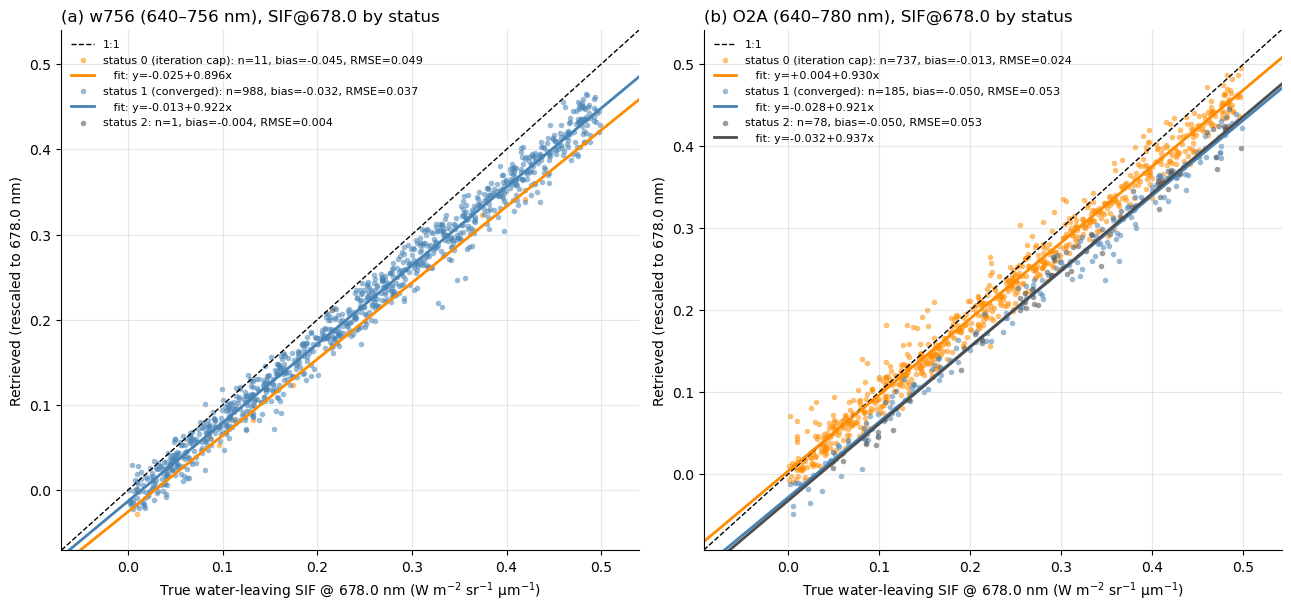

In [7]:
import h5py
from scipy.interpolate import CubicSpline

with h5py.File("/home/zhe2/data/MyProjects/PACE_redSIF_PACE/Files_in_use/SIF_singular_vector.jld2", "r") as f:
    sv_wl = np.asarray(f["SIF_wavelen"][()]).ravel()
    u1 = CubicSpline(sv_wl, f["SIF_U"][()][0, :], bc_type="natural")   # Julia SIF_U[:, 1]

STATUS_STYLE = {0: ("#FF8C00", "0 (iteration cap)"), 1: ("#4682B4", "1 (converged)"), 2: ("0.3", "2")}
fig, axes = plt.subplots(1, len(retrievals), figsize=(6.4 * len(retrievals), 6), layout="constrained", squeeze=False)
for ax, (name, r), letter in zip(axes[0], retrievals.items(), "ab"):
    t = r.sif_678_amplitude.values
    ret = r.sif_678_ret.values * u1(678.0) / u1(float(r.attrs["sif_band_nm"]))
    st = r.status.values
    lim = np.array([np.nanmin(np.r_[t, ret]), np.nanmax(np.r_[t, ret])])
    lim += np.array([-1, 1]) * 0.08 * np.ptp(lim)
    ax.plot(lim, lim, "k--", lw=1, label="1:1")
    for s, (col, lab) in STATUS_STYLE.items():
        m = (st == s) & np.isfinite(ret)
        if not m.any():
            continue
        d = ret[m] - t[m]
        ax.scatter(t[m], ret[m], s=16, color=col, alpha=0.55, lw=0,
                   label=f"status {lab}: n={m.sum()}, bias={d.mean():+.3f}, RMSE={np.sqrt(np.mean(d**2)):.3f}")
        if m.sum() >= 10:
            b1, b0 = np.polyfit(t[m], ret[m], 1)
            ax.plot(lim, b0 + b1 * lim, color=col, lw=2, label=f"   fit: y={b0:+.3f}+{b1:.3f}x")
    ax.set_xlim(*lim)
    ax.set_ylim(*lim)
    ax.set_xlabel(f"True water-leaving SIF @ 678.0 nm ({UNITS})")
    ax.set_ylabel("Retrieved (rescaled to 678.0 nm)")
    ax.set_title(f"({letter}) {name}, SIF@678.0 by status", loc="left")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()


### SIF retrieval bias vs viewing zenith angle

With n = 1000 the bias has only a weak AOD dependence (Spearman ρ ≈ −0.1 to −0.2); it is dominated by a SIF-proportional term that grows with the view path. The retrieval models TOA SIF as `T↑ · SIF` with `T↑ = exp(PCs·c)` (gas transmittance only),
whereas in the RT the upwelling SIF is also attenuated by Rayleigh/aerosol scattering along the view path, which grows as 1/cos(VZA).
If that is the cause, the ratio retrieved/true SIF should fall roughly as exp(−k/cos VZA), and the absolute error should scale with SIF.

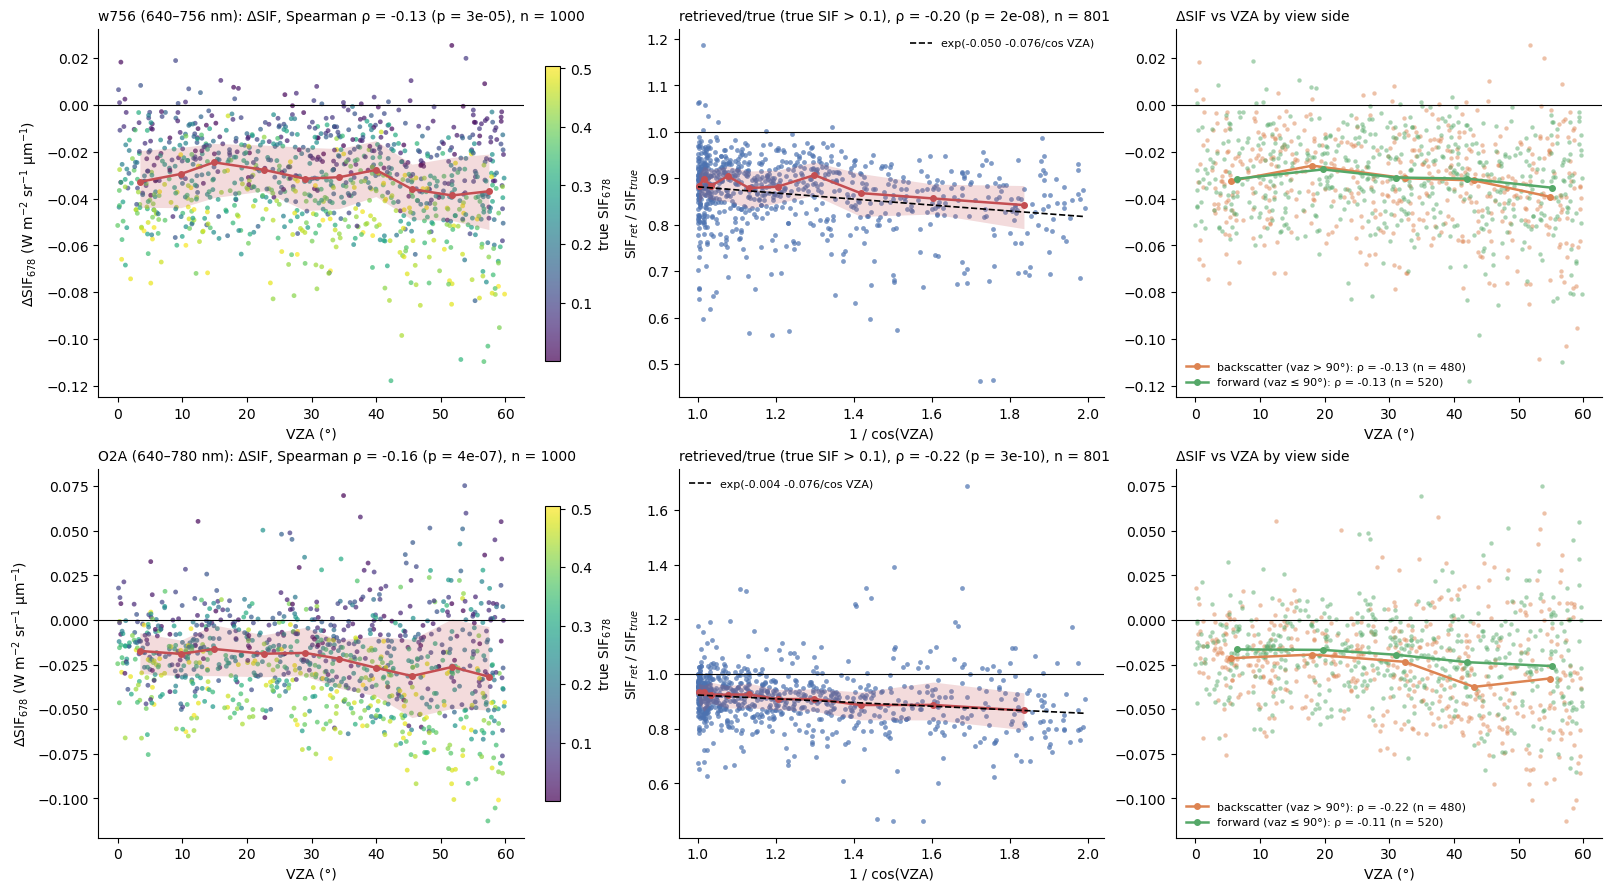

In [8]:
# ΔSIF and retrieved/true ratio against VZA
vza = rt_samples.vza.values
vaz = rt_samples.vaz.values
inv_mu_v = 1 / np.cos(np.radians(vza))

fig, axes = plt.subplots(len(res), 3, figsize=(16, 4.4 * len(res)), layout="constrained")
for row, (name, v) in enumerate(res.items()):
    sel = v["sel"]
    nbin = 10 if sel.sum() >= 150 else 5
    y = v["delta"][sel]
    x = vza[sel]

    # (a) absolute error vs VZA, coloured by true SIF
    ax = axes[row, 0]
    sc = ax.scatter(x, y, s=12, c=sif_678_true[sel], cmap="viridis", alpha=0.7, linewidths=0)
    mid, med, q1, q3 = binned_median(x, y, np.quantile(x, np.linspace(0, 1, nbin + 1)))
    ax.fill_between(mid, q1, q3, color="#C44E52", alpha=0.2, linewidth=0)
    ax.plot(mid, med, "o-", color="#C44E52", lw=1.8, ms=4, label="binned median (IQR)")
    ax.axhline(0, color="k", lw=0.8)
    rho, p = stats.spearmanr(x, y)
    ax.set_title(f"{name}: ΔSIF, Spearman ρ = {rho:+.2f} (p = {p:.1g}), n = {sel.sum()}", loc="left", fontsize=10)
    ax.set_xlabel("VZA (°)")
    ax.set_ylabel(f"ΔSIF$_{{678}}$ ({UNITS})")
    fig.colorbar(sc, ax=ax, label="true SIF$_{678}$", shrink=0.8)

    # (b) ratio retrieved/true vs 1/cos(VZA) for true SIF > 0.1, with exp(−k/μv) fit
    ax = axes[row, 1]
    big = sel & (sif_678_true > 0.1)
    ratio = (v["delta"][big] + sif_678_true[big]) / sif_678_true[big]
    xb = inv_mu_v[big]
    ax.scatter(xb, ratio, s=12, color="#4C72B0", alpha=0.7, linewidths=0)
    mid, med, q1, q3 = binned_median(xb, ratio, np.quantile(xb, np.linspace(0, 1, nbin + 1)))
    ax.fill_between(mid, q1, q3, color="#C44E52", alpha=0.2, linewidth=0)
    ax.plot(mid, med, "o-", color="#C44E52", lw=1.8, ms=4)
    # log(ratio) = log(a) − k/μv  (a: VZA-independent scale, k: effective slant-path optical depth)
    good = ratio > 0
    kfit, lna = np.polyfit(xb[good], np.log(ratio[good]), 1)
    xx = np.linspace(1, xb.max(), 50)
    ax.plot(xx, np.exp(lna + kfit * xx), "k--", lw=1.2,
            label=f"exp({lna:+.3f} {kfit:+.3f}/cos VZA)")
    ax.axhline(1, color="k", lw=0.8)
    rho, p = stats.spearmanr(xb, ratio)
    ax.set_title(f"retrieved/true (true SIF > 0.1), ρ = {rho:+.2f} (p = {p:.1g}), n = {big.sum()}", loc="left", fontsize=10)
    ax.set_xlabel("1 / cos(VZA)")
    ax.set_ylabel("SIF$_{ret}$ / SIF$_{true}$")
    ax.legend(frameon=False, fontsize=8)

    # (c) ΔSIF vs VZA split by view side
    ax = axes[row, 2]
    for lab, m, col in (("backscatter (vaz > 90°)", vaz > 90, "#DD8452"), ("forward (vaz ≤ 90°)", vaz <= 90, "#55A868")):
        mm = sel & m
        xs, ys = vza[mm], v["delta"][mm]
        ax.scatter(xs, ys, s=10, color=col, alpha=0.5, linewidths=0)
        mid, med, q1, q3 = binned_median(xs, ys, np.quantile(xs, np.linspace(0, 1, max(nbin // 2, 3) + 1)), min_n=5)
        rho, p = stats.spearmanr(xs, ys)
        ax.plot(mid, med, "o-", color=col, lw=1.8, ms=4, label=f"{lab}: ρ = {rho:+.2f} (n = {mm.sum()})")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title("ΔSIF vs VZA by view side", loc="left", fontsize=10)
    ax.set_xlabel("VZA (°)")
    ax.legend(frameon=False, fontsize=8)
    for a in axes[row]:
        a.spines[["top", "right"]].set_visible(False)
plt.show()

In [9]:
# multiple regression: which terms carry the bias?
#   ΔSIF = c0 + c1·SIF + c2·SIF·(1/cos VZA − 1) + c3·(albedo − 0.015) + c4·AOD678 + c5·(1/cos SZA − 1.5)
alb = rt_samples.surface_albedo.values
inv_mu_s = 1 / np.cos(np.radians(rt_samples.sza.values))
names = ["const", "SIF", "SIF·(1/cos VZA − 1)", "albedo − 0.015", "AOD678", "1/cos SZA − 1.5"]
for name, v in res.items():
    sel = v["sel"]
    t = sif_678_true[sel]
    X = np.c_[np.ones(sel.sum()), t, t * (inv_mu_v[sel] - 1), alb[sel] - 0.015, aod_678[sel], inv_mu_s[sel] - 1.5]
    yv = v["delta"][sel]
    b, *_ = np.linalg.lstsq(X, yv, rcond=None)
    r = yv - X @ b
    se = np.sqrt(np.sum(r**2) / (len(yv) - X.shape[1]) * np.diag(np.linalg.inv(X.T @ X)))
    print(f"{name} (n = {sel.sum()}, {STATUS_LABEL}):  R² = {1 - np.sum(r**2) / np.sum((yv - yv.mean())**2):.2f}, "
          f"residual SD {r.std():.4f} vs ΔSIF SD {yv.std():.4f}")
    for n_, bb, s in zip(names, b, se):
        print(f"    {n_:22s} {bb:+.4f} ± {s:.4f}   (|t| = {abs(bb) / s:.1f})")

w756 (640–756 nm) (n = 1000, all status):  R² = 0.44, residual SD 0.0145 vs ΔSIF SD 0.0195
    const                  -0.0081 ± 0.0011   (|t| = 7.5)
    SIF                    -0.0648 ± 0.0036   (|t| = 18.1)
    SIF·(1/cos VZA − 1)    -0.0530 ± 0.0060   (|t| = 8.8)
    albedo − 0.015         -0.4078 ± 0.0801   (|t| = 5.1)
    AOD678                 -0.0807 ± 0.0098   (|t| = 8.2)
    1/cos SZA − 1.5        +0.0053 ± 0.0010   (|t| = 5.2)
O2A (640–780 nm) (n = 1000, all status):  R² = 0.55, residual SD 0.0172 vs ΔSIF SD 0.0257
    const                  -0.0051 ± 0.0013   (|t| = 4.0)
    SIF                    -0.0624 ± 0.0042   (|t| = 14.7)
    SIF·(1/cos VZA − 1)    -0.0692 ± 0.0071   (|t| = 9.7)
    albedo − 0.015         +2.2985 ± 0.0946   (|t| = 24.3)
    AOD678                 +0.0509 ± 0.0116   (|t| = 4.4)
    1/cos SZA − 1.5        -0.0052 ± 0.0012   (|t| = 4.3)
